## 1. Import Libraries

This notebook analyzes the model trained in **03_model_training.ipynb** (the latest augmented CNN experiment).

We will load the same preprocessed dataset and the saved model, then evaluate it on the held-out test set. Threshold selection, if needed, will use the validation set only.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print(f"TensorFlow Version: {tf.__version__}")

TensorFlow Version: 2.21.0


## 2. Load Preprocessed Data

Load the train, validation, and test arrays created during preprocessing.

The test set is reserved for final evaluation. We will use the validation set for threshold analysis, not the test set.

In [2]:
data_path = "../dataset/preprocessed_data.npz"

if not os.path.exists(data_path):
    data_path = "dataset/preprocessed_data.npz"

data = np.load(data_path)

X_val = data["X_val"]
y_val = data["y_val"]

X_test = data["X_test"]
y_test = data["y_test"]

print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Validation: (13015, 80, 80, 1) (13015,)
Test: (12309, 80, 80, 1) (12309,)


## 3. Load the Latest Trained CNN

Load the model saved by **03_model_training.ipynb**.

The training notebook saves this model as `drowsiness_cnn_experiment_2.keras`.

In [3]:
model_path = "../models/drowsiness_cnn_experiment_2.keras"

if not os.path.exists(model_path):
    model_path = "models/drowsiness_cnn_experiment_2.keras"

if not os.path.exists(model_path):
    raise FileNotFoundError(
        f"Could not find the Experiment 2 model at: {model_path}. "
        "Check the model save location in 03_model_training.ipynb."
    )

model = tf.keras.models.load_model(model_path)

print("Latest Experiment 2 model loaded successfully!")
model.summary()

print("Total trainable parameters:", model.count_params())

Latest Experiment 2 model loaded successfully!


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)       │ (None, 80, 80, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 78, 78, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_6 (MaxPooling2D)       │ (None, 39, 39, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 37, 37, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_7 (MaxPooling2D)       │ (None, 18, 18, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 16, 16, 128)         │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_8 (MaxPooling2D)       │ (None, 8, 8, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 128)                 │          16,512 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 128)                 │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_2 (Dropout)                  │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 328,965 (1.25 MB)

 Trainable params: 109,569 (428.00 KB)

 Non-trainable params: 256 (1.00 KB)

 Optimizer params: 219,140 (856.02 KB)

Total trainable parameters: 109825


## 4. Generate Test Predictions

Generate probability scores for the test images. The sigmoid output represents the predicted probability of the eye being **Open (class 1)**.

Using the default threshold of 0.5:
- Probability below 0.5 → Closed (0)
- Probability greater than or equal to 0.5 → Open (1)

In [4]:
# Generate test probabilities once
y_pred_probs = model.predict(X_test, verbose=0).ravel()

# Convert probabilities into class labels using threshold = 0.5
y_pred = (y_pred_probs >= 0.5).astype(int)

print(f"Generated {len(y_pred)} test predictions.")

incorrect_indices = np.where(y_pred != y_test)[0]

print("Total test images:", len(y_test))
print("Correct predictions:", len(y_test) - len(incorrect_indices))
print("Incorrect predictions:", len(incorrect_indices))
print("Error rate:", round(len(incorrect_indices) / len(y_test) * 100, 2), "%")

Generated 12309 test predictions.
Total test images: 12309
Correct predictions: 11804
Incorrect predictions: 505
Error rate: 4.1 %


In [5]:


# Get predictions from the trained model
y_prob = model.predict(X_test, verbose=0).ravel()

# Convert probabilities into class labels
y_pred = (y_prob >= 0.5).astype(int)

# Find incorrect predictions
incorrect_indices = np.where(y_pred != y_test)[0]

print("Total test images:", len(y_test))
print("Incorrect predictions:", len(incorrect_indices))
print("Correct predictions:", len(y_test) - len(incorrect_indices))
print("Error rate:", round(len(incorrect_indices) / len(y_test) * 100, 2), "%")

Total test images: 12309
Incorrect predictions: 505
Correct predictions: 11804
Error rate: 4.1 %


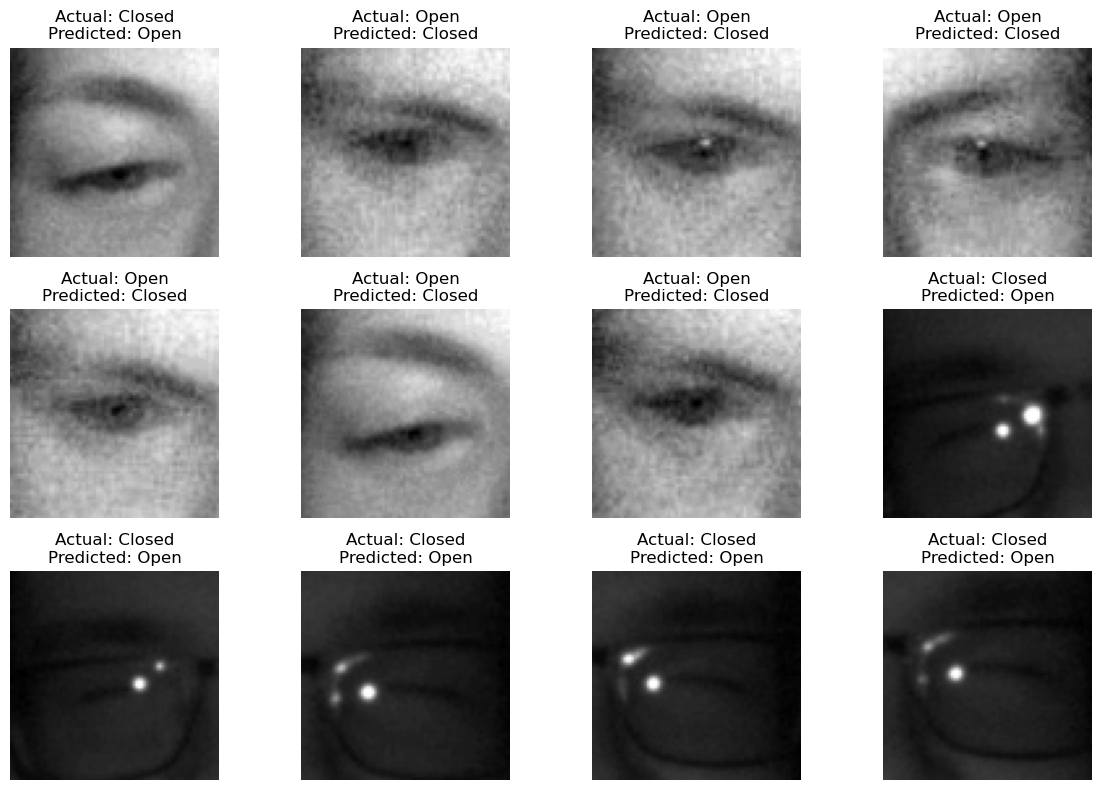

In [6]:

# Display up to 12 incorrect predictions
n = min(12, len(incorrect_indices))

plt.figure(figsize=(12, 8))

for i in range(n):
    idx = incorrect_indices[i]

    actual = "Closed" if y_test[idx] == 0 else "Open"
    predicted = "Closed" if y_pred[idx] == 0 else "Open"

    plt.subplot(3, 4, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Actual closed, predicted open
missed_closed = np.where(
    (y_test == 0) & (y_pred == 1)
)[0]

# Actual open, predicted closed
missed_open = np.where(
    (y_test == 1) & (y_pred == 0)
)[0]

print("Closed eyes predicted as open:", len(missed_closed))
print("Open eyes predicted as closed:", len(missed_open))

Closed eyes predicted as open: 224
Open eyes predicted as closed: 281


In [9]:
# Predict probabilities on the validation set
val_prob = model.predict(X_val, verbose=0).ravel()

print("Validation Threshold Analysis")
print("-" * 50)

for threshold in [0.30, 0.35, 0.40, 0.45, 0.50, 0.55, 0.60]:

    val_pred = (val_prob >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val,
        val_pred,
        labels=[0, 1]
    ).ravel()

    val_accuracy = (tn + tp) / len(y_val)
    closed_recall = tn / (tn + fp) if (tn + fp) > 0 else 0
    open_recall = tp / (tp + fn) if (tp + fn) > 0 else 0

    print(f"\nThreshold: {threshold:.2f}")
    print(f"Validation Accuracy: {val_accuracy * 100:.2f}%")
    print(f"Closed-eye recall: {closed_recall * 100:.2f}%")
    print(f"Open-eye recall: {open_recall * 100:.2f}%")
    print(f"Closed predicted as open: {fp}")
    print(f"Open predicted as closed: {fn}")

Validation Threshold Analysis
--------------------------------------------------

Threshold: 0.30
Validation Accuracy: 97.03%
Closed-eye recall: 95.67%
Open-eye recall: 98.32%
Closed predicted as open: 273
Open predicted as closed: 113

Threshold: 0.35
Validation Accuracy: 97.14%
Closed-eye recall: 96.18%
Open-eye recall: 98.05%
Closed predicted as open: 241
Open predicted as closed: 131

Threshold: 0.40
Validation Accuracy: 97.27%
Closed-eye recall: 96.62%
Open-eye recall: 97.88%
Closed predicted as open: 213
Open predicted as closed: 142

Threshold: 0.45
Validation Accuracy: 97.33%
Closed-eye recall: 97.03%
Open-eye recall: 97.62%
Closed predicted as open: 187
Open predicted as closed: 160

Threshold: 0.50
Validation Accuracy: 97.41%
Closed-eye recall: 97.46%
Open-eye recall: 97.36%
Closed predicted as open: 160
Open predicted as closed: 177

Threshold: 0.55
Validation Accuracy: 97.44%
Closed-eye recall: 97.81%
Open-eye recall: 97.09%
Closed predicted as open: 138
Open predicted as c

## 6. Final Performance Metrics on the Test Set

The following metrics use the default classification threshold of 0.5. These are final test-set results, not validation results.

In [10]:
# Evaluate test loss and accuracy
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)

print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}\n")

class_names = ["Closed (0)", "Open (1)"]

print("Classification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=class_names,
        zero_division=0
    )
)

Test Accuracy: 95.90%
Test Loss: 0.1171

Classification Report:
              precision    recall  f1-score   support

  Closed (0)       0.95      0.96      0.96      6082
    Open (1)       0.96      0.95      0.96      6227

    accuracy                           0.96     12309
   macro avg       0.96      0.96      0.96     12309
weighted avg       0.96      0.96      0.96     12309



## 7. Confusion Matrix

The confusion matrix shows the number of correctly and incorrectly classified closed-eye and open-eye images.

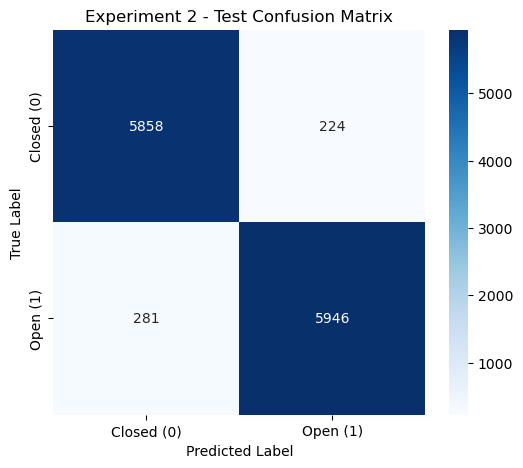

In [11]:
cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Experiment 2 - Test Confusion Matrix")
plt.show()

## 8. Correct Predictions

Visualize a few test images that the model classified correctly.

Total Correct Predictions: 11804


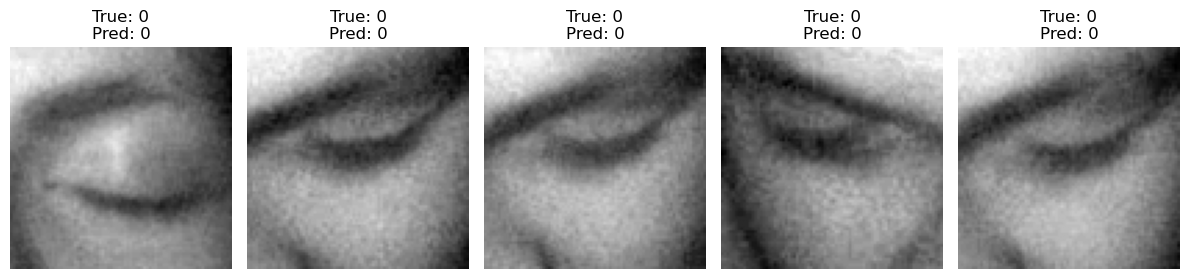

In [12]:
# Find indices of correct predictions
correct_indices = np.where(y_pred == y_test)[0]
print(f"Total Correct Predictions: {len(correct_indices)}")

# Plot some correct predictions
plt.figure(figsize=(12, 4))
for i, idx in enumerate(correct_indices[:5]):
    plt.subplot(1, 5, i + 1)
    plt.imshow(X_test[idx].squeeze(), cmap="gray")
    plt.title(f"True: {y_test[idx]}\nPred: {y_pred[idx]}")
    plt.axis("off")
plt.tight_layout()
plt.show()


## 9. Incorrect Predictions

Inspect a few misclassified test images. These examples can help identify challenging lighting, eye position, glasses, reflections, or ambiguous eye states.

Total Incorrect Predictions: 505


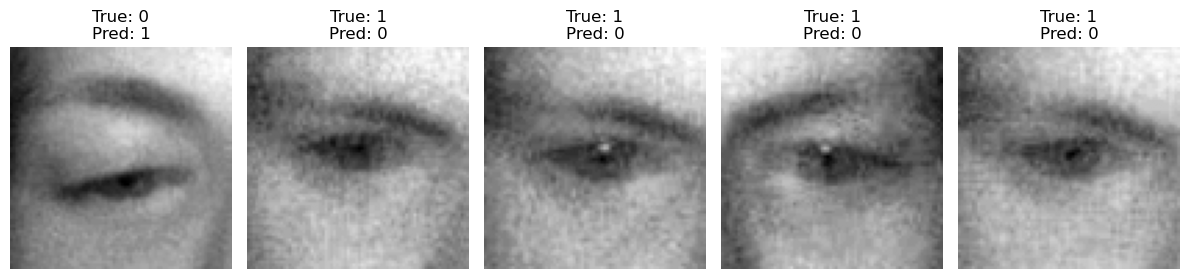

In [13]:
# Find indices of incorrect predictions
incorrect_indices = np.where(y_pred != y_test)[0]
print(f"Total Incorrect Predictions: {len(incorrect_indices)}")

if len(incorrect_indices) > 0:
    plt.figure(figsize=(12, 4))
    for i, idx in enumerate(incorrect_indices[:min(5, len(incorrect_indices))]):
        plt.subplot(1, 5, i + 1)
        plt.imshow(X_test[idx].squeeze(), cmap="gray")
        plt.title(f"True: {y_test[idx]}\nPred: {y_pred[idx]}")
        plt.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("No incorrect predictions found!")


## 10. Prediction Confidence

The histogram shows the model's predicted probability of **Open (class 1)** for each true class. The dashed line is the default decision threshold of 0.5.

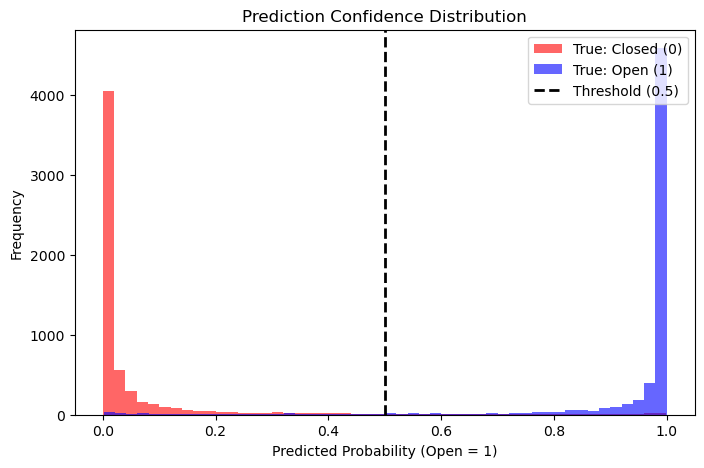

In [14]:
plt.figure(figsize=(8, 5))
plt.hist(y_pred_probs[y_test == 0], bins=50, alpha=0.6, color='red', label='True: Closed (0)')
plt.hist(y_pred_probs[y_test == 1], bins=50, alpha=0.6, color='blue', label='True: Open (1)')
plt.axvline(0.5, color='black', linestyle='dashed', linewidth=2, label='Threshold (0.5)')
plt.xlabel("Predicted Probability (Open = 1)")
plt.ylabel("Frequency")
plt.title("Prediction Confidence Distribution")
plt.legend()
plt.show()


## 11. Final Model Analysis

Summarize the latest Experiment 2 model's test performance. Interpret the closed-eye recall carefully because predicting a closed eye as open is an important failure mode for a drowsiness-monitoring system.

In [15]:
# Final Analysis Summary

print("Final Analysis Summary")
print("-" * 35)
print("Model:", os.path.basename(model_path))
print("Trainable parameters:", model.count_params())
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")
print("Misclassifications:", len(incorrect_indices), "out of", len(y_test))
print(f"Error rate: {len(incorrect_indices) / len(y_test) * 100:.2f}%")
print("\nClosed-eye recall and other class-wise metrics are shown in the classification report above.")
print("-" * 35)
print("Note: Threshold analysis above uses validation data only. The test set is evaluated at threshold 0.5.")

Final Analysis Summary
-----------------------------------
Model: drowsiness_cnn_experiment_2.keras
Trainable parameters: 109825
Test Accuracy: 95.90%
Test Loss: 0.1171
Misclassifications: 505 out of 12309
Error rate: 4.10%

Closed-eye recall and other class-wise metrics are shown in the classification report above.
-----------------------------------
Note: Threshold analysis above uses validation data only. The test set is evaluated at threshold 0.5.
